# Multi-class Network Intrusion Detection on UNSW-NB15

The goal is to classify network flows into **normal traffic** or one of **nine attack categories**
(Fuzzers, Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms) using the
UNSW-NB15 dataset.

The dataset is heavily imbalanced, so the focus is not only on building a classifier but on
evaluating it honestly: how well does it detect the *rare* attacks, not just the common ones?

**Contents**
1. Data loading
2. Exploratory data analysis
3. Feature encoding
4. Preprocessing
5. Baseline models
6. Handling class imbalance
7. Model comparison
8. Per-class performance
9. Why accuracy is misleading here
10. Discussion

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (RANDOM_STATE, TARGET, NOMINAL_COLS, load_unsw_nb15,
                      numeric_feature_columns, encode_features, split_and_scale)

np.random.seed(RANDOM_STATE)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 13
sns.set_style('whitegrid')

FIG_DIR = os.path.abspath('../figures')
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=120, bbox_inches='tight')

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.tree import DecisionTreeClassifier

## 1. Data loading

The dataset is downloaded from Kaggle with `kagglehub` (Parquet version, cached locally after the first run).

- `UNSW_NB15_training-set.parquet` and `UNSW_NB15_testing-set.parquet` contain the network-flow records.
- The feature-description and event-list CSVs are metadata only and are not used for modelling.

The two record files are combined and re-split with a fixed seed so that the class stratification is fully controlled.

In [2]:
df = load_unsw_nb15()
print(f'Combined shape: {df.shape}')
df.head(3)

Combined shape: (257673, 36)


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,0,0,1,1,0,0,0,0,Normal,0


## 2. Exploratory data analysis

In [3]:
print(f'Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}')
print(f'Missing values: {df.isna().sum().sum()}')
print()
print('Column dtypes:')
print(df.dtypes.astype(str).value_counts())
df.describe().T.head(15)

Rows: 257,673  |  Columns: 36
Missing values: 0

Column dtypes:
float32     11
int16        9
int8         7
int32        3
str          2
int64        2
category     1
object       1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
dur,257673.0,1.246715e+00,5.974306e+00,0.0,0.000008,0.004285,6.857770e-01,5.999999e+01
spkts,257673.0,1.977714e+01,1.359472e+02,1.0,2.000000,4.000000,1.200000e+01,1.064600e+04
dpkts,257673.0,1.851470e+01,1.119860e+02,0.0,0.000000,2.000000,1.000000e+01,1.101800e+04
sbytes,257673.0,8.572952e+03,1.737739e+05,24.0,114.000000,528.000000,1.362000e+03,1.435577e+07
dbytes,257673.0,1.438729e+04,1.461993e+05,0.0,0.000000,178.000000,1.064000e+03,1.465753e+07
rate,257673.0,9.125391e+04,1.603446e+05,0.0,30.789276,2955.664795,1.250000e+05,1.000000e+06
sload,257673.0,7.060869e+07,1.857312e+08,0.0,12318.004883,743942.312500,8.000000e+07,5.988000e+09
dload,257673.0,6.582142e+05,2.412372e+06,0.0,0.000000,1747.441284,2.210538e+04,2.242273e+07
sloss,257673.0,4.889317e+00,6.557495e+01,0.0,0.000000,0.000000,3.000000e+00,5.319000e+03
dloss,257673.0,6.743691e+00,5.370222e+01,0.0,0.000000,0.000000,2.000000e+00,5.507000e+03


In [4]:
class_counts = df[TARGET].value_counts()
classes_sorted = sorted(df[TARGET].unique())

print('Class distribution:')
print(class_counts)
print(f'\nNumber of classes: {df[TARGET].nunique()}')
print(f'Imbalance ratio (largest / smallest): {class_counts.max() / class_counts.min():.0f}x')

Class distribution:
attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174
Name: count, dtype: int64

Number of classes: 10
Imbalance ratio (largest / smallest): 534x


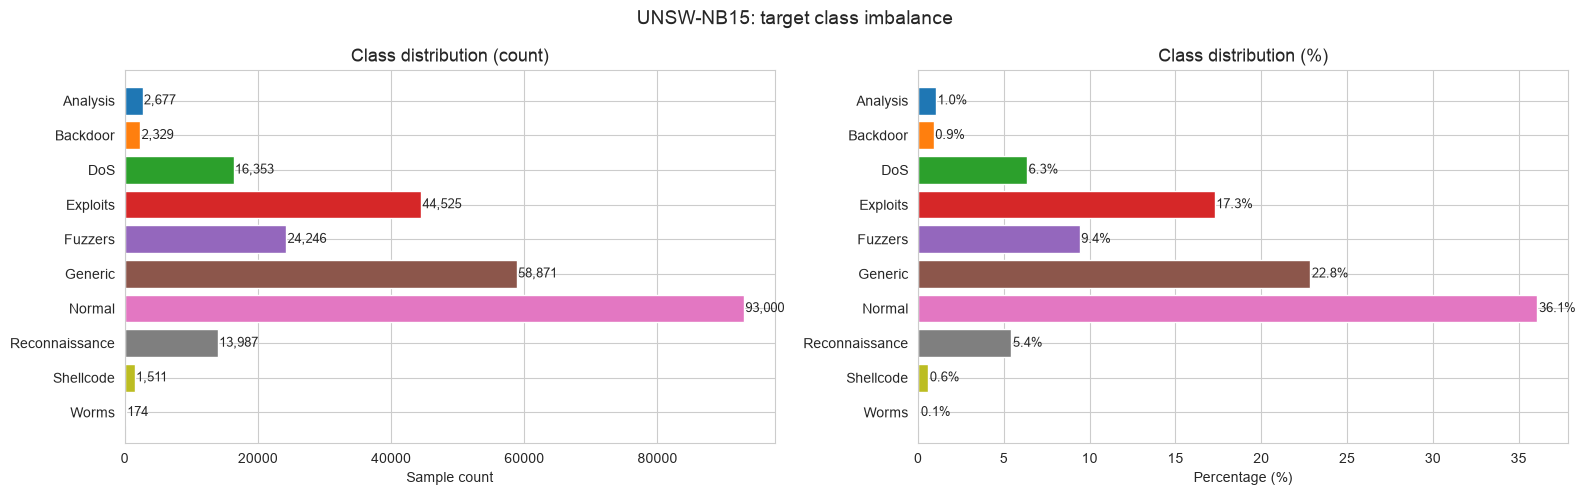

In [5]:
counts = np.array([class_counts[c] for c in classes_sorted])
cmap_cls = plt.get_cmap('tab10', len(classes_sorted))
cls_colors = [cmap_cls(i) for i in range(len(classes_sorted))]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].barh(classes_sorted[::-1], counts[::-1], color=cls_colors[::-1], edgecolor='white')
axes[0].set_title('Class distribution (count)')
axes[0].set_xlabel('Sample count')
for i, v in enumerate(counts[::-1]):
    axes[0].text(v + 200, i, f'{v:,}', va='center', fontsize=9)

pct = counts / counts.sum() * 100
axes[1].barh(classes_sorted[::-1], pct[::-1], color=cls_colors[::-1], edgecolor='white')
axes[1].set_title('Class distribution (%)')
axes[1].set_xlabel('Percentage (%)')
for i, v in enumerate(pct[::-1]):
    axes[1].text(v + 0.1, i, f'{v:.1f}%', va='center', fontsize=9)

plt.suptitle('UNSW-NB15: target class imbalance', fontsize=14)
plt.tight_layout()
save('class_distribution')
plt.show()

In [6]:
num_cols = numeric_feature_columns(df)

print(f'Numeric features: {len(num_cols)}')
print(f'Nominal features: {NOMINAL_COLS}')
for col in NOMINAL_COLS:
    print(f'  {col}: {df[col].nunique()} unique values')

Numeric features: 31
Nominal features: ['proto', 'service', 'state']
  proto: 133 unique values
  service: 13 unique values
  state: 11 unique values


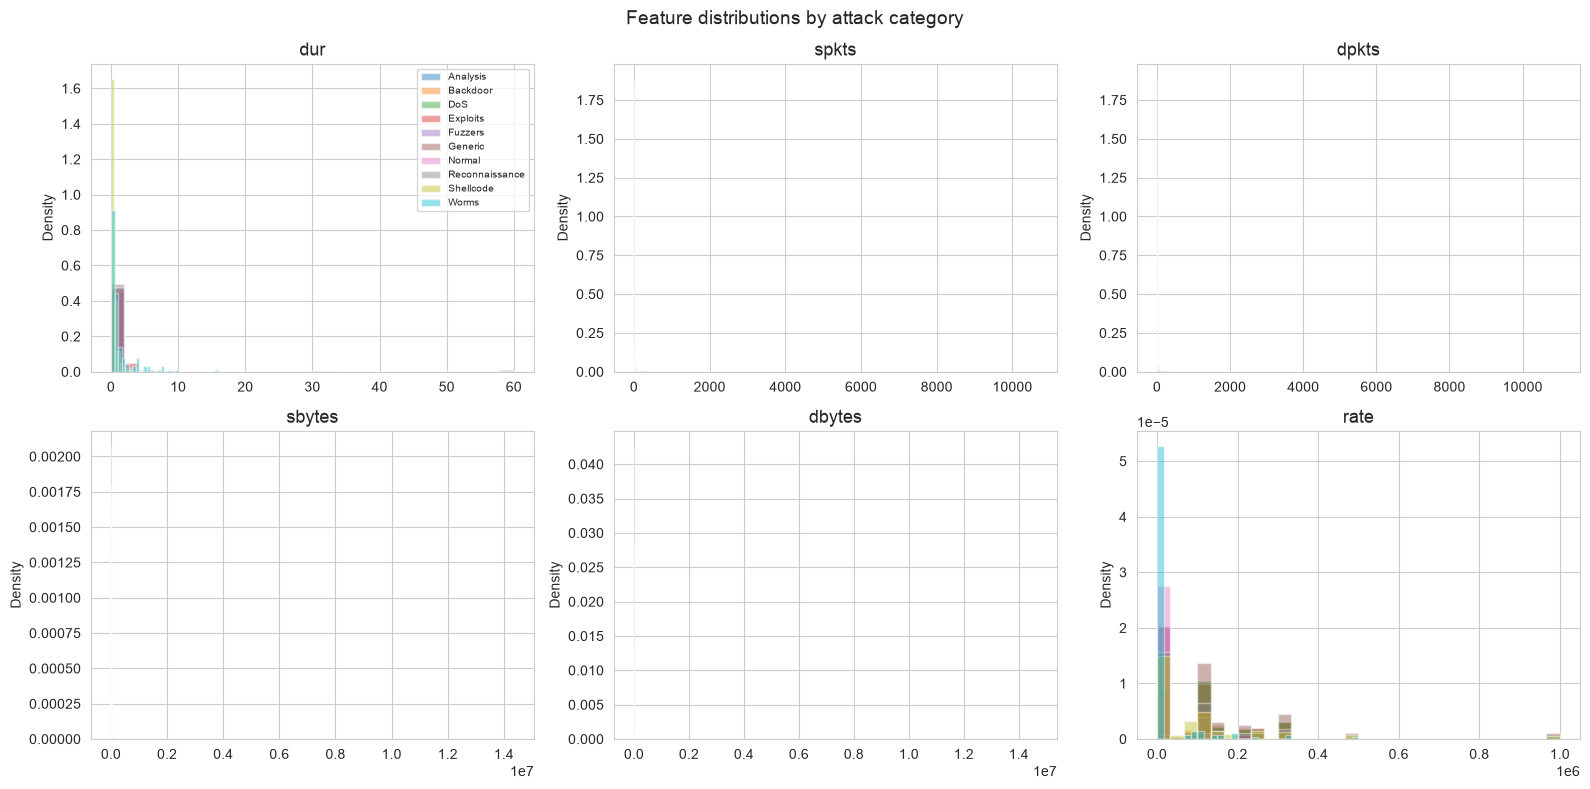

In [7]:
plot_feats = num_cols[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, feat in enumerate(plot_feats):
    for j, cls in enumerate(classes_sorted):
        vals = df.loc[df[TARGET] == cls, feat].dropna().astype(float)
        axes[i].hist(vals, bins=30, alpha=0.45, label=cls, color=cmap_cls(j), density=True)
    axes[i].set_title(feat)
    axes[i].set_ylabel('Density')

axes[0].legend(fontsize=7)
plt.suptitle('Feature distributions by attack category', fontsize=14)
plt.tight_layout()
plt.show()

## 3. Feature encoding

Three features are nominal: `proto`, `service` and `state`.

**Chosen strategy: one-hot encoding (OHE)**

- They have no natural ordering. TCP, UDP and ICMP are qualitatively different; none is "greater" than another.
- **Label encoding** (TCP=0, UDP=1, ICMP=2) would impose a false order. Tree models would learn splits such as
  `proto > 1.5` that group unrelated protocols just because their integer codes are adjacent.
- **OHE** gives independent binary columns (`proto_tcp`, `proto_udp`, ...), so every split is interpretable
  ("is this TCP traffic?"). This matters for intrusion detection, where attack types often have strong protocol signatures.
- The cardinality is manageable (proto ~130, service ~13, state ~11), so the extra columns are acceptable.
- **Target encoding** was considered but rejected: it leaks label information unless it is fitted strictly inside each CV fold.

In [8]:
X_encoded, y_raw = encode_features(df)
feature_names = X_encoded.columns.tolist()

print(f'Shape before OHE: {df.drop(columns=["id", "label", TARGET], errors="ignore").shape}')
print(f'Shape after  OHE: {X_encoded.shape}')

Shape before OHE: (257673, 34)
Shape after  OHE: (257673, 188)


## 4. Preprocessing

80/20 stratified split, so every class (including Worms) appears in both sets in the same proportion.
`StandardScaler` is fitted on the training set only to avoid leaking test statistics.

In [9]:
X_train_s, X_test_s, y_train, y_test, scaler = split_and_scale(X_encoded, y_raw)

print(f'Train: {X_train_s.shape[0]:,} | Test: {X_test_s.shape[0]:,} | Features: {X_train_s.shape[1]}')
print()
print('Train class distribution:')
print(y_train.value_counts())

Train: 206,138 | Test: 51,535 | Features: 188

Train class distribution:
attack_cat
Normal            74400
Generic           47097
Exploits          35620
Fuzzers           19397
DoS               13082
Reconnaissance    11189
Analysis           2142
Backdoor           1863
Shellcode          1209
Worms               139
Name: count, dtype: int64


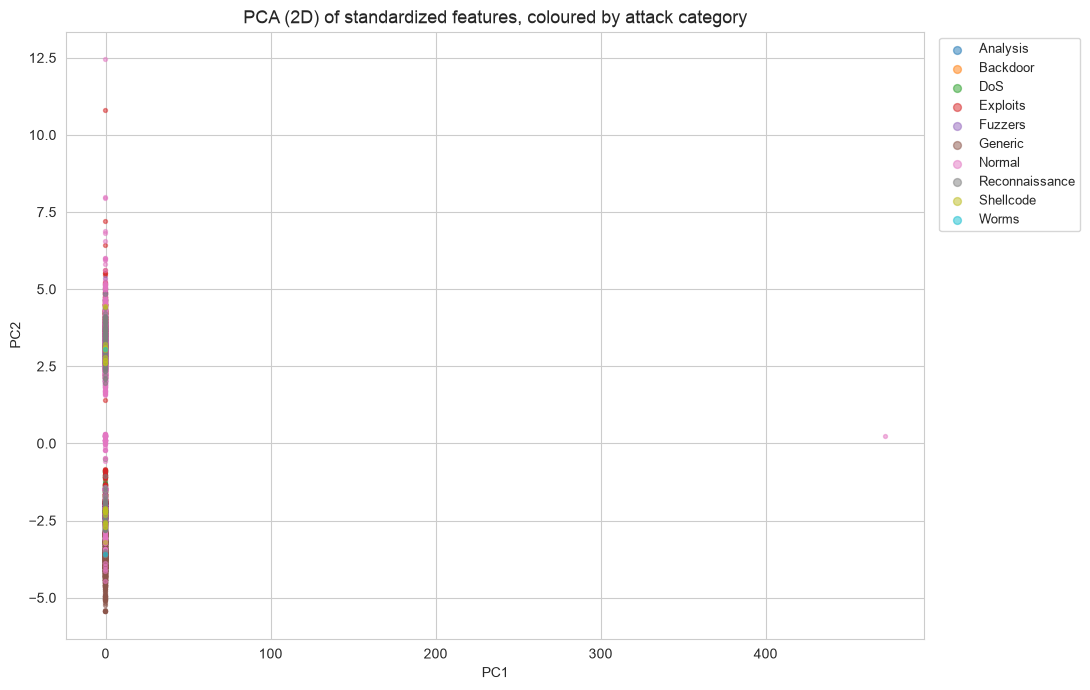

In [10]:
idx_s = np.random.choice(X_train_s.shape[0], 5000, replace=False)
X_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_s[idx_s])
y_2d = y_train.values[idx_s]

plt.figure(figsize=(11, 7))
for i, cls in enumerate(classes_sorted):
    mask = (y_2d == cls)
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], s=8, alpha=0.5, color=cmap_cls(i), label=cls)
plt.title('PCA (2D) of standardized features, coloured by attack category')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(markerscale=2, bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.tight_layout()
save('pca_2d')
plt.show()

## 5. Baseline models

Four models of increasing capacity, all trained on the same data:

- **Dummy** (always predicts the majority class) as a sanity floor
- **Decision tree** (max depth 10)
- **Logistic regression** (multinomial, linear)
- **Random forest** (100 trees)

**Macro F1** is the primary metric, because it weights every class equally regardless of size.

In [11]:
def eval_clf(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return {
        'Model':       name,
        'Accuracy':    accuracy_score(y_te, pred),
        'Macro F1':    f1_score(y_te, pred, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_te, pred, average='weighted', zero_division=0),
        'Macro Prec':  precision_score(y_te, pred, average='macro', zero_division=0),
        'Macro Rec':   recall_score(y_te, pred, average='macro', zero_division=0),
        'pred':        pred,
        'estimator':   model,
    }

def to_table(results):
    return pd.DataFrame([{k: v for k, v in r.items() if k not in ['pred', 'estimator']} for r in results])

baseline_defs = [
    ('Dummy (most frequent)', DummyClassifier(strategy='most_frequent')),
    ('Decision Tree', DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)),
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ('Random Forest', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
]

baseline_results = []
for name, model in baseline_defs:
    r = eval_clf(name, model, X_train_s, X_test_s, y_train, y_test)
    baseline_results.append(r)
    print(f'{name:<24} Accuracy={r["Accuracy"]:.4f}  Macro F1={r["Macro F1"]:.4f}')

to_table(baseline_results).round(4)

Dummy (most frequent)    Accuracy=0.3609  Macro F1=0.0530


Decision Tree            Accuracy=0.7735  Macro F1=0.4517


Logistic Regression      Accuracy=0.7364  Macro F1=0.3449


Random Forest            Accuracy=0.8157  Macro F1=0.5270


,Model,Accuracy,Macro F1,Weighted F1,Macro Prec,Macro Rec
0,Dummy (most frequent),0.3609,0.0530,0.1914,0.0361,0.1000
1,Decision Tree,0.7735,0.4517,0.7600,0.6243,0.4544
2,Logistic Regression,0.7364,0.3449,0.6995,0.4240,0.3571
3,Random Forest,0.8157,0.5270,0.8022,0.6733,0.4980


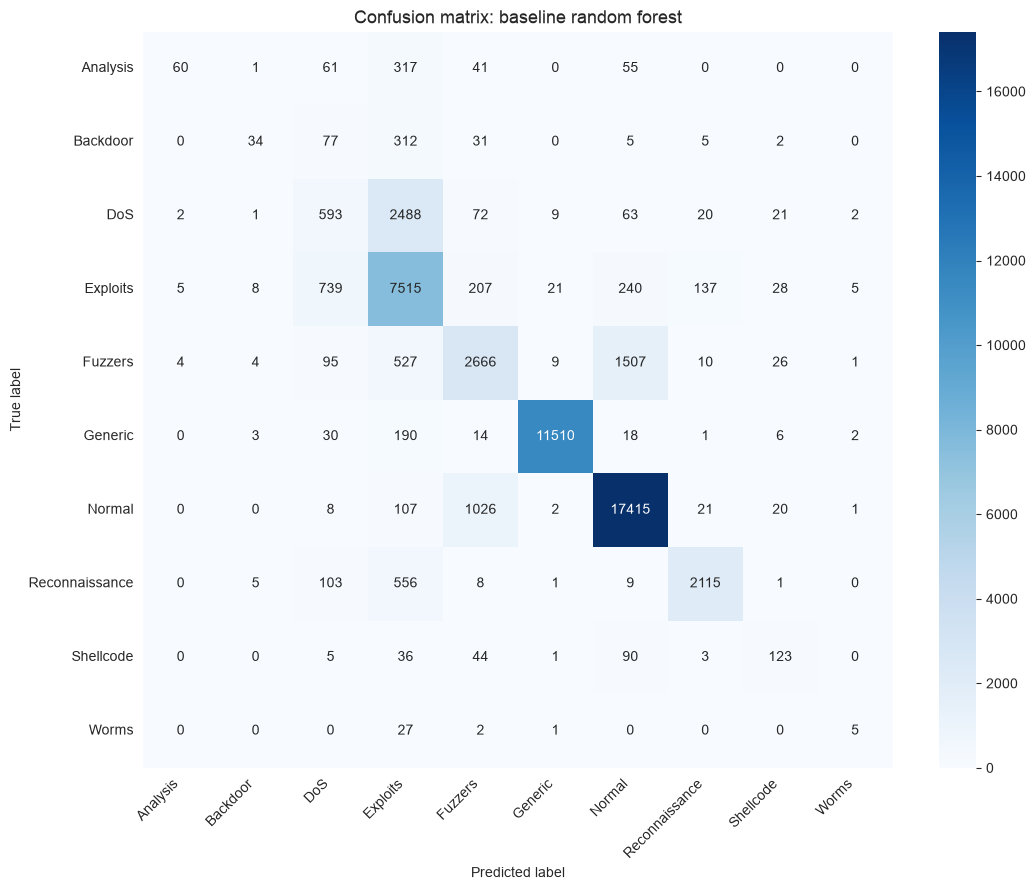

                precision    recall  f1-score   support

      Analysis       0.85      0.11      0.20       535
      Backdoor       0.61      0.07      0.13       466
           DoS       0.35      0.18      0.24      3271
      Exploits       0.62      0.84      0.72      8905
       Fuzzers       0.65      0.55      0.60      4849
       Generic       1.00      0.98      0.99     11774
        Normal       0.90      0.94      0.92     18600
Reconnaissance       0.91      0.76      0.83      2798
     Shellcode       0.54      0.41      0.47       302
         Worms       0.31      0.14      0.20        35

      accuracy                           0.82     51535
     macro avg       0.67      0.50      0.53     51535
  weighted avg       0.81      0.82      0.80     51535



In [12]:
rf_base = next(r for r in baseline_results if r['Model'] == 'Random Forest')

plt.figure(figsize=(11, 9))
sns.heatmap(confusion_matrix(y_test, rf_base['pred'], labels=classes_sorted),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=classes_sorted, yticklabels=classes_sorted)
plt.title('Confusion matrix: baseline random forest')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(classification_report(y_test, rf_base['pred'], labels=classes_sorted, zero_division=0))

## 6. Handling class imbalance

`Normal` (~36%) and `Generic` (~23%) dominate, while `Worms` has only 174 samples (<0.1%).
Two techniques are compared:

**1. `class_weight='balanced'`**: scales each sample's loss by the inverse frequency of its class,
so mistakes on rare classes cost more. No extra data is created.

**2. SMOTE**: creates synthetic minority samples by interpolating between nearest neighbours.
To keep memory use reasonable, the minority classes are oversampled up to 10,000 samples each
instead of all the way up to the size of the majority class.

In [13]:
weighted_defs = [
    ('Decision Tree (balanced)',
     DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=RANDOM_STATE)),
    ('Logistic Regression (balanced)',
     LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    ('Random Forest (balanced)',
     RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
]

weighted_results = []
for name, model in weighted_defs:
    r = eval_clf(name, model, X_train_s, X_test_s, y_train, y_test)
    weighted_results.append(r)
    print(f'{name:<32} Accuracy={r["Accuracy"]:.4f}  Macro F1={r["Macro F1"]:.4f}')

Decision Tree (balanced)         Accuracy=0.7112  Macro F1=0.4941


Logistic Regression (balanced)   Accuracy=0.6114  Macro F1=0.3688


Random Forest (balanced)         Accuracy=0.7554  Macro F1=0.5455


In [14]:
from imblearn.over_sampling import SMOTE

train_counts = y_train.value_counts()
target_n = 10_000
strategy = {cls: target_n for cls, n in train_counts.items() if n < target_n}

smote = SMOTE(sampling_strategy=strategy, k_neighbors=5, random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train_s, y_train)

print(f'Before SMOTE: {X_train_s.shape[0]:,} samples')
print(f'After  SMOTE: {X_train_sm.shape[0]:,} samples')
print()
print(pd.Series(y_train_sm).value_counts())

smote_results = [eval_clf(
    'Random Forest + SMOTE',
    RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    X_train_sm, X_test_s, y_train_sm, y_test,
)]
r = smote_results[0]
print(f'\n{r["Model"]:<32} Accuracy={r["Accuracy"]:.4f}  Macro F1={r["Macro F1"]:.4f}')

Before SMOTE: 206,138 samples
After  SMOTE: 240,785 samples

attack_cat
Normal            74400
Generic           47097
Exploits          35620
Fuzzers           19397
DoS               13082
Reconnaissance    11189
Analysis          10000
Backdoor          10000
Shellcode         10000
Worms             10000
Name: count, dtype: int64



Random Forest + SMOTE            Accuracy=0.8127  Macro F1=0.5475


## 7. Model comparison

In [15]:
all_results = baseline_results + weighted_results + smote_results

df_all = to_table(all_results).sort_values('Macro F1', ascending=False).reset_index(drop=True)
df_all.round(4)

,Model,Accuracy,Macro F1,Weighted F1,Macro Prec,Macro Rec
0,Random Forest + SMOTE,0.8127,0.5475,0.8018,0.5534,0.5704
1,Random Forest (balanced),0.7554,0.5455,0.7870,0.5543,0.5710
2,Random Forest,0.8157,0.5270,0.8022,0.6733,0.4980
3,Decision Tree (balanced),0.7112,0.4941,0.7451,0.4895,0.6426
4,Decision Tree,0.7735,0.4517,0.7600,0.6243,0.4544
5,Logistic Regression (balanced),0.6114,0.3688,0.6680,0.3991,0.5355
6,Logistic Regression,0.7364,0.3449,0.6995,0.4240,0.3571
7,Dummy (most frequent),0.3609,0.0530,0.1914,0.0361,0.1000


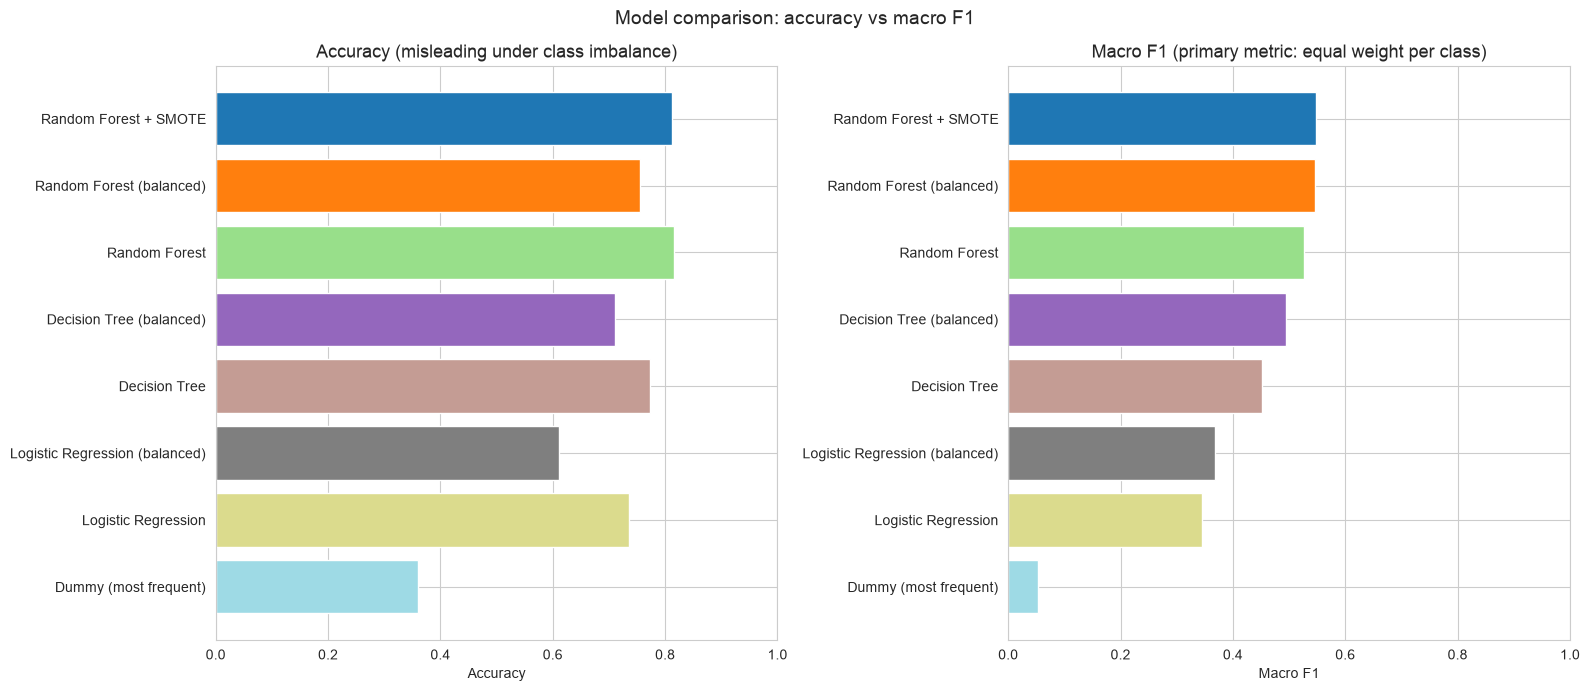

In [16]:
bar_colors = [plt.get_cmap('tab20', len(df_all))(i) for i in range(len(df_all))]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(df_all['Model'], df_all['Accuracy'], color=bar_colors, edgecolor='white')
axes[0].set_title('Accuracy (misleading under class imbalance)')
axes[0].set_xlabel('Accuracy')
axes[0].set_xlim(0, 1)
axes[0].invert_yaxis()

axes[1].barh(df_all['Model'], df_all['Macro F1'], color=bar_colors, edgecolor='white')
axes[1].set_title('Macro F1 (primary metric: equal weight per class)')
axes[1].set_xlabel('Macro F1')
axes[1].set_xlim(0, 1)
axes[1].invert_yaxis()

plt.suptitle('Model comparison: accuracy vs macro F1', fontsize=14)
plt.tight_layout()
save('model_comparison')
plt.show()

## 8. Per-class performance of the best model

In [17]:
best_name = df_all.loc[0, 'Model']
best_result = next(r for r in all_results if r['Model'] == best_name)

print(f'Best model:  {best_name}')
print(f'Accuracy:    {best_result["Accuracy"]:.4f}')
print(f'Macro F1:    {best_result["Macro F1"]:.4f}')
print(f'Weighted F1: {best_result["Weighted F1"]:.4f}')
print()
print(classification_report(y_test, best_result['pred'], labels=classes_sorted, zero_division=0))

Best model:  Random Forest + SMOTE
Accuracy:    0.8127
Macro F1:    0.5475
Weighted F1: 0.8018



                precision    recall  f1-score   support

      Analysis       0.20      0.14      0.17       535
      Backdoor       0.14      0.15      0.14       466
           DoS       0.35      0.15      0.21      3271
      Exploits       0.63      0.83      0.72      8905
       Fuzzers       0.67      0.54      0.60      4849
       Generic       1.00      0.98      0.99     11774
        Normal       0.90      0.93      0.92     18600
Reconnaissance       0.92      0.75      0.83      2798
     Shellcode       0.41      0.69      0.51       302
         Worms       0.31      0.54      0.40        35

      accuracy                           0.81     51535
     macro avg       0.55      0.57      0.55     51535
  weighted avg       0.80      0.81      0.80     51535



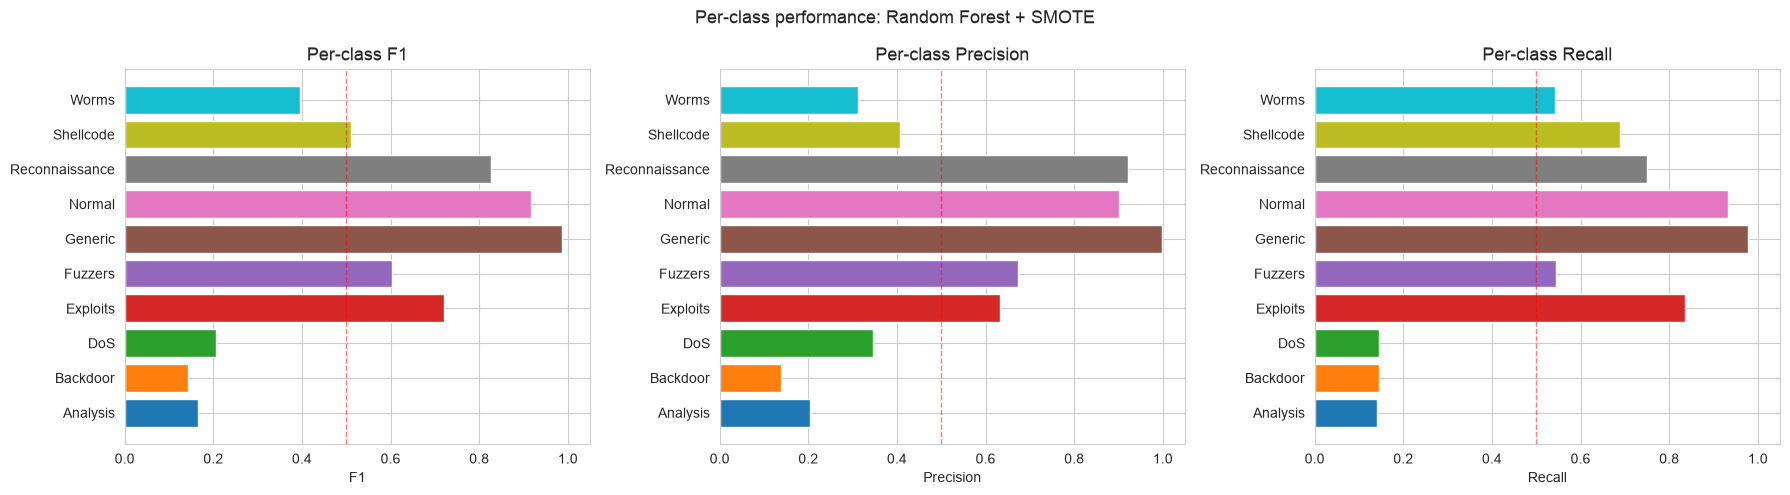

,F1,Precision,Recall,Support
Backdoor,0.1424,0.1391,0.1459,466
Analysis,0.1659,0.2033,0.1402,535
DoS,0.2056,0.3469,0.1461,3271
Worms,0.3958,0.3115,0.5429,35
Shellcode,0.5117,0.4070,0.6887,302
Fuzzers,0.6021,0.6742,0.5440,4849
Exploits,0.7199,0.6328,0.8349,8905
Reconnaissance,0.8270,0.9203,0.7509,2798
Normal,0.9171,0.9018,0.9330,18600
Generic,0.9871,0.9972,0.9772,11774


In [18]:
report = classification_report(y_test, best_result['pred'], labels=classes_sorted,
                               output_dict=True, zero_division=0)

per_class = pd.DataFrame({
    'F1':        [report[c]['f1-score'] for c in classes_sorted],
    'Precision': [report[c]['precision'] for c in classes_sorted],
    'Recall':    [report[c]['recall'] for c in classes_sorted],
    'Support':   [int(report[c]['support']) for c in classes_sorted],
}, index=classes_sorted)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ['F1', 'Precision', 'Recall']):
    ax.barh(classes_sorted, per_class[metric], color=cls_colors, edgecolor='white')
    ax.set_title(f'Per-class {metric}')
    ax.set_xlabel(metric)
    ax.set_xlim(0, 1.05)
    ax.axvline(0.5, color='red', linestyle='--', linewidth=1, alpha=0.5)

plt.suptitle(f'Per-class performance: {best_name}', fontsize=13)
plt.tight_layout()
save('per_class_performance')
plt.show()

per_class.round(4).sort_values('F1')

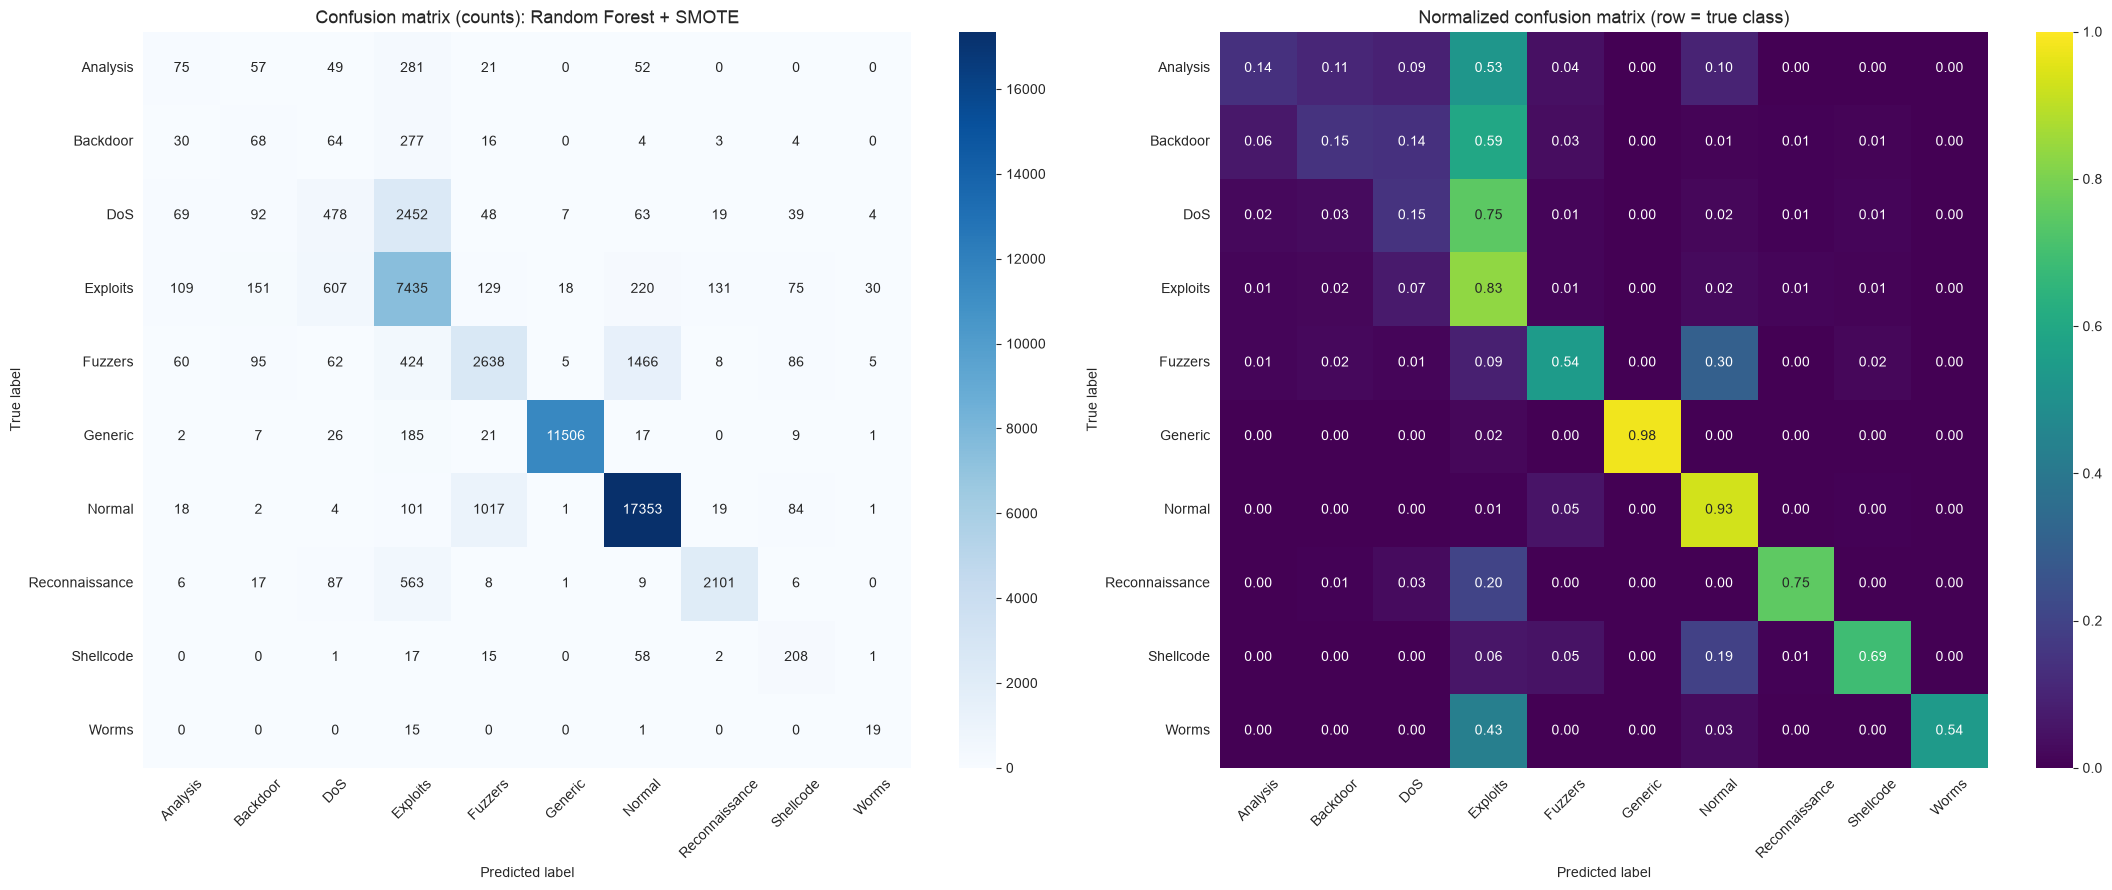

In [19]:
cm_best = confusion_matrix(y_test, best_result['pred'], labels=classes_sorted)
cm_norm = cm_best.astype(float) / cm_best.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes_sorted, yticklabels=classes_sorted, ax=axes[0])
axes[0].set_title(f'Confusion matrix (counts): {best_name}')
axes[0].set_ylabel('True label')
axes[0].set_xlabel('Predicted label')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='viridis',
            xticklabels=classes_sorted, yticklabels=classes_sorted, vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('Normalized confusion matrix (row = true class)')
axes[1].set_ylabel('True label')
axes[1].set_xlabel('Predicted label')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
save('confusion_matrix')
plt.show()

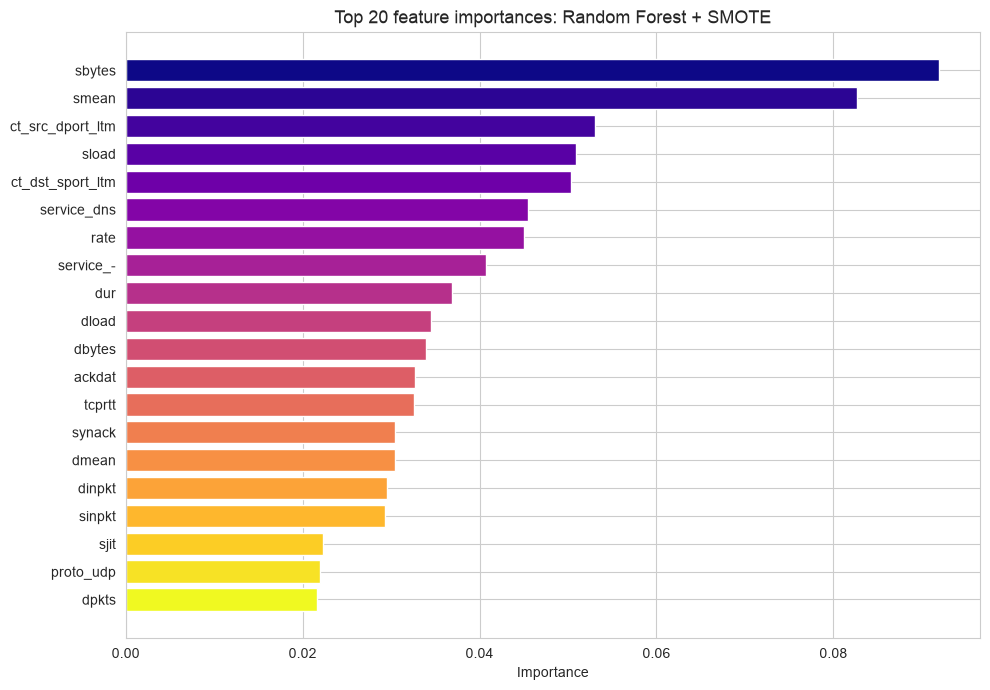

In [20]:
if hasattr(best_result['estimator'], 'feature_importances_'):
    importances = best_result['estimator'].feature_importances_
    top_k = 20
    top_idx = np.argsort(importances)[-top_k:][::-1]
    top_feats = [feature_names[i] for i in top_idx]
    top_vals = importances[top_idx]

    fi_colors = [plt.get_cmap('plasma', top_k)(i) for i in range(top_k)]

    plt.figure(figsize=(10, 7))
    plt.barh(top_feats[::-1], top_vals[::-1], color=fi_colors[::-1], edgecolor='white')
    plt.title(f'Top {top_k} feature importances: {best_name}')
    plt.xlabel('Importance')
    plt.tight_layout()
    save('feature_importance')
    plt.show()

## 9. Why accuracy is misleading here

In [21]:
majority_cls = y_train.value_counts().index[0]
majority_pct = y_train.value_counts().iloc[0] / len(y_train) * 100
dummy = next(r for r in baseline_results if r['Model'].startswith('Dummy'))

print(f'Majority class: "{majority_cls}" ({majority_pct:.1f}% of the training data)')
print()
print('A model that always predicts the majority class gets:')
print(f'  Accuracy: {dummy["Accuracy"]:.4f}')
print(f'  Macro F1: {dummy["Macro F1"]:.4f}')
print()
df_all[['Model', 'Accuracy', 'Macro F1', 'Weighted F1']].round(4)

Majority class: "Normal" (36.1% of the training data)

A model that always predicts the majority class gets:
  Accuracy: 0.3609
  Macro F1: 0.0530



,Model,Accuracy,Macro F1,Weighted F1
0,Random Forest + SMOTE,0.8127,0.5475,0.8018
1,Random Forest (balanced),0.7554,0.5455,0.7870
2,Random Forest,0.8157,0.5270,0.8022
3,Decision Tree (balanced),0.7112,0.4941,0.7451
4,Decision Tree,0.7735,0.4517,0.7600
5,Logistic Regression (balanced),0.6114,0.3688,0.6680
6,Logistic Regression,0.7364,0.3449,0.6995
7,Dummy (most frequent),0.3609,0.0530,0.1914


## 10. Discussion

### Encoding

`proto`, `service` and `state` are nominal, so one-hot encoding was used instead of label encoding.
Label encoding would let a tree split on `proto > 1.5` and group unrelated protocols just because their
integer codes are adjacent. With OHE every split is a clean yes/no question about one protocol, service or
connection state, which suits intrusion detection where many attack types have a characteristic protocol signature.
Three one-hot columns (`service_dns`, `service_-` and `proto_udp`) make it into the forest's top-20 features,
next to volume and timing features such as `sbytes`, `smean` and `sload`.

### Effect of imbalance handling

| Model | Accuracy | Macro F1 |
|---|---|---|
| Random forest (baseline) | 0.816 | 0.527 |
| Random forest, `class_weight='balanced'` | 0.755 | 0.546 |
| Random forest + SMOTE (minorities up to 10k) | 0.813 | 0.548 |

- **Without any handling**, the forest is accurate on the large classes but almost blind to the small ones:
  Worms recall is 0.14 and Backdoor recall is 0.07.
- **Class weighting** improves macro F1, but it pays for it with a 6-point drop in accuracy. Pushing the model
  towards rare classes makes it predict them too often, which shows up as lower precision on the larger classes.
- **SMOTE** gives the best macro F1 while keeping accuracy almost at the baseline level. The largest gains are
  on the rarest classes: Worms recall goes from 0.14 to 0.54 and Shellcode recall from 0.41 to 0.69.

### What is still hard

`Backdoor`, `Analysis` and `DoS` stay below 0.25 F1 for every model. The confusion matrix shows that 53-75% of
their rows are predicted as `Exploits`. A second, smaller problem is `Fuzzers`, where 30% of rows are predicted as `Normal`.
Notebook 02 shows why: for these classes a large share of the rows have *exactly the same feature vector*
as rows labelled with a different class. No classifier can separate identical inputs, so this is a limit
of the features, not of the model.

### Why accuracy is misleading

The dummy model that always answers `Normal` gets 36% accuracy with zero useful detection. More importantly,
the baseline forest reaches 82% accuracy while missing most Worms, Backdoor and Analysis traffic, because those
classes together make up less than 2% of the test set and barely move the accuracy number.

**Macro F1** gives every class the same weight, so it exposes exactly the weakness that matters operationally:
an intrusion-detection system that looks accurate but misses rare attack types gives false confidence.
Macro F1 is therefore used as the primary metric throughout.